In [17]:
import os, pickle, time

import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from utils.tv_var.periodic_var import PeriodicVAR, select_order

#### VARX Results

In [8]:
point = 'p102'

#### Predictores: 30 PCs de presión + 10 PCs del gradiente reconstruido (6 h)
pcs_msl = pd.read_csv('outputs/pca/pcs_msl_30_6h.csv', index_col=0, parse_dates=True)
pcs_grad = pd.read_csv('outputs/grad_rec/pcs_grad_rec_6h.csv', index_col=0, parse_dates=True)

data_pcs = pcs_msl.join(pcs_grad)
data_pcs = data_pcs.resample('h').interpolate()

#### Objetivo: Z (PIT + armónica, 00_PIT), media móvil de 6 h centrada, a 00/06/12/18
waves_df_z = pd.read_csv(f'outputs/marginal/z_bulk_{point}.csv', index_col=0, parse_dates=True)

#### Para volver a metros
pit = pickle.load(open(f'outputs/marginal/transformacion_{point}.pkl', 'rb'))

In [9]:
waves_df_z_train = waves_df_z.loc['1985-01-01':'2015-12-31'][['VHM0']]
waves_df_z_test = waves_df_z.loc['1985-01-01':'2015-12-31'][['VHM0']]

data_pcs_train = data_pcs.loc['1985-01-01':'2015-12-31']
data_pcs_test = data_pcs.loc['1985-01-01':'2015-12-31']

#### Train Period

In [10]:
lags_pc = [0, 6, 12, 18, 24, 30, 36]
exog = pd.concat({f"l{l}": data_pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags_pc}, axis=1).reindex(data_pcs.index)
exog.columns = [f"{c}_l{l[1:]}" for l, c in exog.columns]
exog = exog.dropna()

exog_train = exog.loc["1985-01-01":"2015-12-31"]
exog_test = exog.loc["2016-01-01":"2025-12-31"]

select_order(waves_df_z_train, p_values=[6, 12, 24, 36, 48], n_harm=0, freq="h", exog=exog_train)

,nobs,loglike,n_params,bic,best
p,,,,,
6,271680,337977.121917,299,-672213.042159,False
12,271680,338054.436778,305,-672292.597600,False
24,271680,338458.161859,317,-672949.899200,False
36,271680,338548.282311,329,-672979.991542,False
48,271680,338722.373520,341,-673178.025398,True


In [11]:
p_var = PeriodicVAR(p=24, n_harm=0, noise_pool='monthly', noise_draw='bootstrap', freq='h')
p_var.fit(data=waves_df_z_train, exog=exog_train)

In [12]:
sims = [p_var.simulate(exog=exog_test, seed=i)["VHM0"] for i in range(20)]

In [13]:
from scipy.signal import find_peaks
from scipy.stats import genextreme
from utils.pit.piece_wise_marginal import from_normal

marg, harm_z = pit["marg"], pit["harm_z"]

def hs_desde_z(z):
    zz = pd.DataFrame({"VHM0": z.values, "VTM02": 0.0}, index=z.index)
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

TEST = ("2016", "2025")
hs_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].asfreq("h")
U90, U99 = hs_obs.loc["1985":"2025"].quantile(0.90), hs_obs.loc["1985":"2025"].quantile(0.99)    # umbrales de siempre (3,73 m)

hs_varx = pd.concat([hs_desde_z(s).rename(i) for i, s in enumerate(sims)], axis=1).loc[TEST[0]:TEST[1]]
hs_hind = pd.read_pickle(f"outputs/ruido/hs_hindcast_{point}.pkl").astype("float64").loc[TEST[0]:TEST[1]]
obs = hs_obs.loc[TEST[0]:TEST[1]]

def duraciones(s, u):
    d = np.diff(np.r_[0, (s.values > u).astype(int), 0])
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def metricas(s):
    s = s.where(obs.reindex(s.index).notna())                                      # mismas horas que el observado
    n_dec = s.dropna().index.year.nunique() / 10
    pk = s.index[find_peaks(s.fillna(0).values, height=U99, distance=72)[0]]
    am = s.groupby(s.index.year).max()
    return {"q99": s.quantile(0.99), "q99.9": s.quantile(0.999), "máximo": s.max(),
            "temporales / década": len(pk) / n_dec, "duración > U99 [h]": duraciones(s.fillna(0), U99).mean(),
            "máx. anual medio": am.mean(), "máx. anual σ": am.std(),
            "Gloria [m]": s.loc["2020-01-18":"2020-01-24"].max(), "Juliette [m]": s.loc["2023-02-25":"2023-03-03"].max()}

m_obs = pd.Series(metricas(obs))
tabla = pd.DataFrame({"observado": m_obs})
for nombre, hs in [("hindcast (2 etapas)", hs_hind), ("VARX", hs_varx)]:
    m = pd.DataFrame([metricas(hs[c]) for c in hs.columns])
    tabla[f"{nombre} p50"] = m.median()
    tabla[f"{nombre} p5–p95"] = [f"{a:.2f}–{b:.2f}" for a, b in zip(m.quantile(0.05), m.quantile(0.95))]
tabla.round(2)

,observado,hindcast (2 etapas) p50,hindcast (2 etapas) p5–p95,VARX p50,VARX p5–p95
q99,3.56,3.65,3.54–3.77,4.93,4.73–5.12
q99.9,5.06,5.19,4.96–5.56,8.61,8.15–9.06
máximo,6.49,6.77,6.26–8.01,10.93,10.93–10.93
temporales / década,56.00,60.00,52.45–69.55,86.00,79.90–97.05
duración > U99 [h],8.52,9.62,8.28–10.64,16.66,15.62–18.81
máx. anual medio,5.52,5.56,5.28–5.80,7.79,7.51–8.26
máx. anual σ,0.43,0.78,0.51–1.06,1.68,1.57–1.94
Gloria [m],5.60,6.39,5.67–8.01,10.93,10.93–10.93
Juliette [m],6.49,4.80,3.66–6.51,5.40,4.44–6.86


In [18]:
import glob
from scipy.stats import genextreme

GEN, N = "h1bb24", 10                                     # 10 simulaciones bastan para ver si se dispara
BLOQUE, A0, A1 = 41, 1941, 2022

def exog_desde(pcs6):
    p = pcs6.resample("h").interpolate()
    e = pd.concat({f"l{l}": p.shift(freq=pd.Timedelta(hours=l)) for l in lags_pc}, axis=1).reindex(p.index)
    e.columns = [f"{c}_l{l[1:]}" for l, c in e.columns]
    return e.dropna()[exog_train.columns]

am_varx, am_emul = [], []
for i, fic in enumerate(sorted(glob.glob(f"outputs/var_6h/simulaciones_{GEN}/sim_*.parquet"))[:N]):
    t = time.time()
    fg = fic.replace("var_6h", "grad_rec").replace("sim_", "grec_")
    pcs6 = pd.read_parquet(fic).astype("float64").join(pd.read_parquet(fg).astype("float64"))
    z = p_var.simulate(exog=exog_desde(pcs6), seed=i)["VHM0"].loc[str(A0):str(A1)]          # el primer año hace de arranque
    hs = hs_desde_z(z)
    am_varx.append(hs.groupby(hs.index.year).max())
    e = pd.read_parquet(f"outputs/emulador/{GEN}/{os.path.basename(fic)}")["VHM0"].astype("float64")
    am_emul.append(e.groupby(e.index.year).max())
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")

bloques = lambda lista: [a.loc[y:y + BLOQUE - 1].values for a in lista for y in range(A0, A1 - BLOQUE + 2, BLOQUE)]
b_varx, b_emul = bloques(am_varx), bloques(am_emul)

sim 00 (21 s)
sim 01 (20 s)
sim 02 (20 s)
sim 03 (19 s)
sim 04 (19 s)
sim 05 (19 s)
sim 06 (19 s)
sim 07 (19 s)
sim 08 (20 s)
sim 09 (20 s)


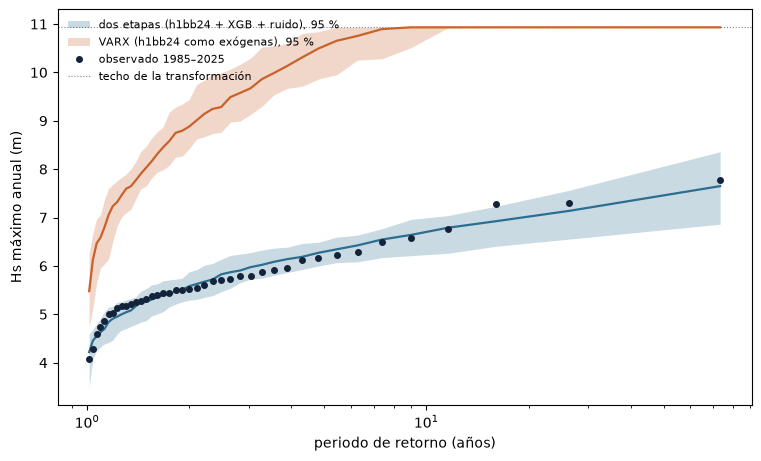

,observado,dos etapas p50,VARX p50
Hs2,5.59,5.56,9.63
Hs10,6.67,6.70,10.77
Hs50,7.43,7.40,10.92
Hs100,7.70,7.67,10.93


In [19]:
#### Periodos de retorno (Gringorten): bandas de bloques de 41 años, VARX vs dos etapas, y observado
def gringorten(am):
    am = np.sort(np.asarray(am)); n = len(am)
    return 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12)), am

am_obs = hs_obs.loc["1985":"2025"].groupby(hs_obs.loc["1985":"2025"].index.year).max()
T_obs, x_obs = gringorten(am_obs)
T_b = gringorten(np.arange(BLOQUE))[0]

fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for b, color, lab in [(b_emul, "#2C6E91", f"dos etapas ({GEN} + XGB + ruido)"), (b_varx, "#C8622A", f"VARX ({GEN} como exógenas)")]:
    ords = np.sort(np.array(b), axis=1).T
    ax.fill_between(T_b, np.percentile(ords, 2.5, axis=1), np.percentile(ords, 97.5, axis=1), color=color, alpha=0.25, lw=0, label=f"{lab}, 95 %")
    ax.plot(T_b, np.median(ords, axis=1), color=color, lw=1.6)
ax.plot(T_obs, x_obs, "o", color="#13233A", ms=4, label="observado 1985–2025")
ax.axhline(hs_desde_z(pd.Series([6.36], index=[pd.Timestamp("2000-01-15")])).iloc[0], color="#7A8594", lw=0.8, ls=":",
           label="techo de la transformación")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig("figuras/alternativas_varx_retorno.png", dpi=200)
plt.show()

#### GEV por bloque: medianas
gev = lambda am: (lambda c, l, s: {f"Hs{T}": genextreme.isf(1 / T, c, l, s) for T in [2, 10, 50, 100]})(*genextreme.fit(am))
pd.DataFrame({"observado": gev(am_obs.values),
              "dos etapas p50": pd.DataFrame([gev(b) for b in b_emul]).median(),
              "VARX p50": pd.DataFrame([gev(b) for b in b_varx]).median()}).round(2)

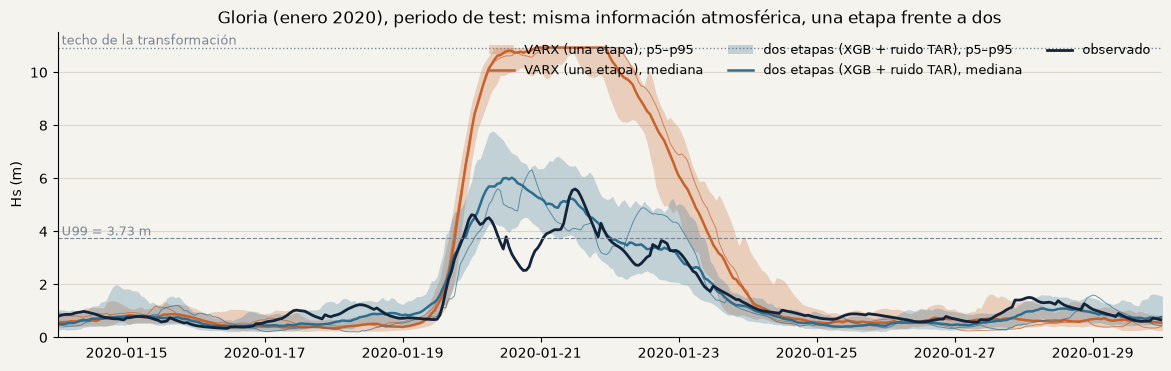

In [20]:
#### Gloria (enero 2020): observado vs dos etapas vs VARX (20 realizaciones, test fuera de muestra)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
t0, t1 = "2020-01-14", "2020-01-30"
techo = hs_desde_z(pd.Series([6.36], index=[pd.Timestamp("2020-01-21")])).iloc[0]

fig, ax = plt.subplots(figsize=(11.6, 3.6), constrained_layout=True, facecolor=FONDO)
for hs, color, lab in [(hs_varx, NARANJA, "VARX (una etapa)"), (hs_hind, AZUL, "dos etapas (XGB + ruido TAR)")]:
    w = hs.loc[t0:t1]
    ax.fill_between(w.index, w.quantile(0.05, axis=1), w.quantile(0.95, axis=1), color=color, alpha=0.25, lw=0,
                    label=f"{lab}, p5–p95")
    ax.plot(w.median(axis=1), color=color, lw=1.8, label=f"{lab}, mediana")
    ax.plot(w.iloc[:, 0], color=color, lw=0.7, alpha=0.7)
ax.plot(obs.loc[t0:t1], color=TINTA, lw=2, label="observado")
ax.axhline(techo, color=GRIS, lw=1, ls=":")
ax.text(pd.Timestamp(t0), techo, " techo de la transformación", color=GRIS, fontsize=9, va="bottom")
ax.axhline(U99, color=GRIS, lw=0.8, ls="--")
ax.text(pd.Timestamp(t0), U99, f" U99 = {U99:.2f} m", color=GRIS, fontsize=9, va="bottom")

ax.set(ylabel="Hs (m)", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)), ylim=(0, techo + 0.6),
       title="Gloria (enero 2020), periodo de test: misma información atmosférica, una etapa frente a dos")
ax.set_facecolor(FONDO)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#DDD8CE", lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper right")

fig.savefig("figuras/alternativas_varx_gloria.png", dpi=200, facecolor=FONDO)
plt.show()

#### Regresión Lineal

In [21]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from xgboost import XGBRegressor
from scipy.signal import find_peaks

#### Mismos predictores y objetivo que el 04: 40 PCs con desfases 0–36 h, Z suavizada 6 h a 00/06/12/18
pcs6 = pcs_msl.join(pcs_grad)
lags = [0, 6, 12, 18, 24, 30, 36]
X_all = pd.concat({f"l{l}": pcs6.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs6.index)
X_all.columns = [f"{c}_l{l[1:]}" for l, c in X_all.columns]
X_all = X_all.dropna()

z6 = waves_df_z["VHM0"].rolling("6h", center=True).mean()
z6 = z6[z6.index.hour.isin([0, 6, 12, 18])].dropna()
idx = X_all.index.intersection(z6.index)
X, y = X_all.loc[idx], z6.loc[idx]
tr = idx < "2016-01-01"

xgb_base = dict(n_estimators=300, learning_rate=0.05, min_child_weight=200, subsample=0.8,
                colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=0)
MODELOS = {
    "lineal (Ridge)":     lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13))),
    "XGB prof. 1 (aditivo)": lambda: XGBRegressor(**xgb_base, max_depth=1),
    "XGB prof. 3 (producción)": lambda: XGBRegressor(**xgb_base, max_depth=3),
}

f_oof, f_test = {}, {}
for nombre, hacer in MODELOS.items():
    f = pd.Series(np.nan, index=X[tr].index)
    for i_fit, i_val in GroupKFold(n_splits=5).split(X[tr], y[tr], groups=X[tr].index.year):
        f.iloc[i_val] = hacer().fit(X[tr].iloc[i_fit], y[tr].iloc[i_fit]).predict(X[tr].iloc[i_val])
    f_oof[nombre] = f
    f_test[nombre] = pd.Series(hacer().fit(X[tr], y[tr]).predict(X[~tr]), index=X.index[~tr])
    print(nombre, "hecho")

lineal (Ridge) hecho
XGB prof. 1 (aditivo) hecho


In [22]:
#### Métricas: correlación, extremos en test y temporales pillados/perdidos (1985–2025, definición oficial)
def hs6(z):                                                       # Z 6-horaria → Hs (m)
    zz = pd.DataFrame({"VHM0": z.values, "VTM02": 0.0}, index=z.index)
    z0 = pit["harm_z"].inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)
    return pd.Series(pit["marg"]["VHM0"].ppf(from_normal(z0).values), index=z.index)

hs_obs_h = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"].loc["1985":"2025"].asfreq("h")
U99 = hs_obs_h.quantile(0.99)
pk_obs = hs_obs_h.index[find_peaks(hs_obs_h.fillna(0).values, height=U99, distance=72)[0]]

filas = {}
for nombre in MODELOS:
    fo, ft = f_oof[nombre], f_test[nombre]
    h_test, h_obs6 = hs6(ft), hs6(y[~tr])
    pk = h_obs6.index[find_peaks(h_obs6.values, height=h_obs6.quantile(0.99), distance=12)[0]]
    rat = pd.Series([h_test.loc[t - pd.Timedelta("24h"):t + pd.Timedelta("24h")].max() / h_obs6.loc[t] for t in pk], index=pk)

    #### temporales oficiales (Hs horaria > U99): pico de Hs(f) en ±24 h / pico observado
    h_all = hs6(pd.concat([fo, ft]).sort_index()).resample("h").interpolate()
    r_all = pd.Series([h_all.loc[t - pd.Timedelta("24h"):t + pd.Timedelta("24h")].max() / hs_obs_h.loc[t] for t in pk_obs])
    filas[nombre] = {"corr OOF 6 h": fo.corr(y[tr]), "corr test 6 h": ft.corr(y[~tr]),
                     "corr test diaria": ft.resample("D").mean().corr(y[~tr].resample("D").mean()),
                     "pico f/obs test": rat.mean(), "10 mayores": rat.loc[h_obs6.loc[pk].nlargest(10).index].mean(),
                     "Juliette [m]": h_test.loc["2023-02-25":"2023-03-03"].max(),
                     "Gloria [m]": h_test.loc["2020-01-18":"2020-01-24"].max(),
                     "perdidos (< 0.5)": (r_all < 0.5).sum(), "pillados (≥ 0.8)": (r_all >= 0.8).sum(),
                     "q99.9 de f (test)": ft.quantile(0.999)}
pd.DataFrame(filas).round(3)

,lineal (Ridge),XGB prof. 1 (aditivo),XGB prof. 3 (producción)
corr OOF 6 h,0.790,0.768,0.848
corr test 6 h,0.789,0.748,0.838
corr test diaria,0.813,0.778,0.866
pico f/obs test,0.997,0.606,0.815
10 mayores,1.116,0.602,0.822
Juliette [m],4.829,3.872,4.654
Gloria [m],10.932,3.703,5.713
perdidos (< 0.5),18.000,77.000,20.000
pillados (≥ 0.8),164.000,17.000,105.000
q99.9 de f (test),3.831,1.876,2.527


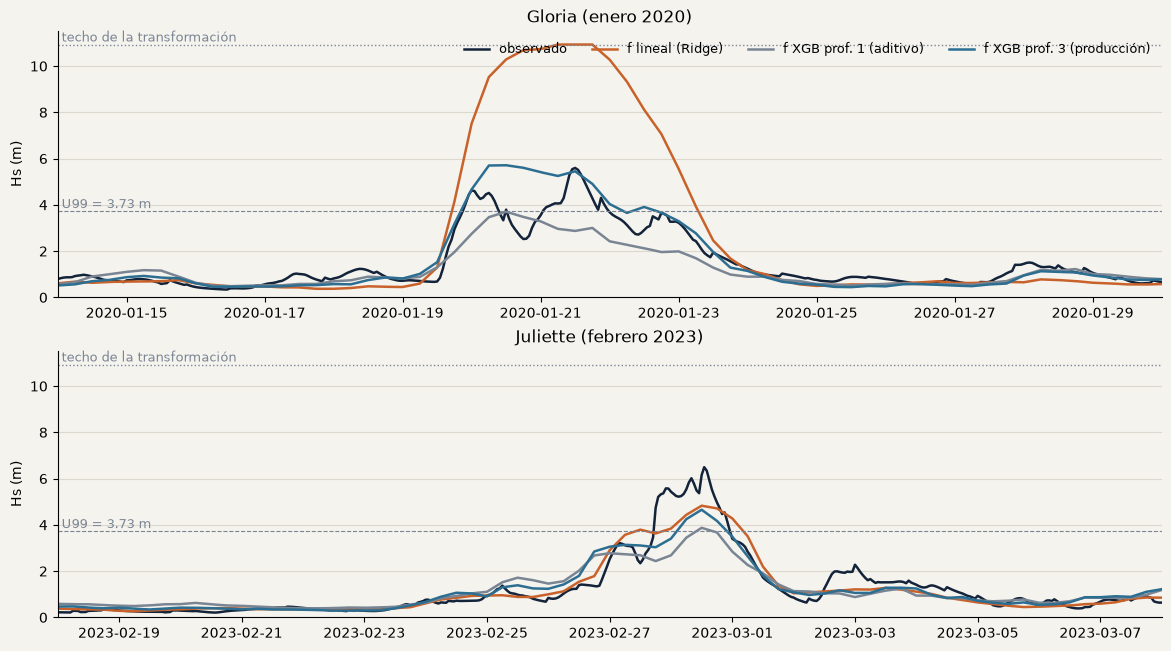

In [23]:
#### Gloria y Juliette (test, fuera de muestra): Hs observada vs Hs de la f de cada modelo, sin ruido
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
COL = {"lineal (Ridge)": NARANJA, "XGB prof. 1 (aditivo)": GRIS, "XGB prof. 3 (producción)": AZUL}
techo = hs6(pd.Series([6.36], index=[pd.Timestamp("2020-01-21")])).iloc[0]
ventanas = [("2020-01-14", "2020-01-30", "Gloria (enero 2020)"), ("2023-02-18", "2023-03-08", "Juliette (febrero 2023)")]

fig, axs = plt.subplots(len(ventanas), 1, figsize=(11.6, 6.4), constrained_layout=True, facecolor=FONDO)
for ax, (t0, t1, titulo) in zip(axs, ventanas):
    ax.plot(hs_obs_h.loc[t0:t1], color=TINTA, lw=1.8, label="observado")
    for nombre, color in COL.items():
        h = hs6(f_test[nombre]).loc[t0:t1].resample("h").interpolate()
        ax.plot(h, color=color, lw=1.8, label=f"f {nombre}")
    ax.axhline(techo, color=GRIS, lw=1, ls=":")
    ax.text(pd.Timestamp(t0), techo, " techo de la transformación", color=GRIS, fontsize=9, va="bottom")
    ax.axhline(U99, color=GRIS, lw=0.8, ls="--")
    ax.text(pd.Timestamp(t0), U99, f" U99 = {U99:.2f} m", color=GRIS, fontsize=9, va="bottom")
    ax.set(ylabel="Hs (m)", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)), ylim=(0, techo + 0.6), title=titulo)
    ax.set_facecolor(FONDO)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#DDD8CE", lw=0.8)
    ax.set_axisbelow(True)
axs[0].legend(frameon=False, fontsize=9, ncol=4, loc="upper right")

fig.savefig("figuras/alternativas_f_gloria_juliette.png", dpi=200, facecolor=FONDO)
plt.show()